# 07 — Uplift Modeling (Step 8)

**Goal:** for every user, predict **how much** showing the ad raises their visit probability: τ(x) = P(visit | ad, x) − P(visit | no ad, x).
Then target the users with the highest τ(x).

**A single user's τ(x) is never observed.** A user is either in treatment or in control, never both.
So ordinary accuracy/AUC does not work. Evaluation happens on **groups**: Qini curve, uplift@k.

| Model | Idea | With 85:15 |
|---|---|---|
| S-Learner | One model, treatment is a feature | Simple; shrinks the effect when it is small |
| T-Learner | Two separate models for treatment and control | The control model trains on little data and is noisy |
| X-Learner | T-learner + imputed effects + propensity weighting | Designed for imbalanced groups |
| **Activity score (baseline)** | Not uplift, just "who is most active" | The simple rule from Step 7; models must beat it |

**Note:** causalml does not install on Python 3.13 / Windows, so all three learners are implemented on LightGBM in `src/uplift_models.py`.

In [1]:
import sys, os, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import mlflow
from sklearn.model_selection import train_test_split

from src.data import load_criteo, FEATURES
from src.uplift_models import SLearner, TLearner, XLearner, ActivityBaseline, DEFAULT_PARAMS
from src.evaluation import (uplift_metrics, bootstrap_metric, paired_bootstrap_diff,
                            uplift_by_bin, qini_curve, uplift_curve, qini_auc_score)

FIG = ROOT / "reports" / "figures"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")

mlflow.set_tracking_uri(f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}")
mlflow.set_experiment("criteo-uplift-visit")
df = load_criteo()
print(df.shape)

2026/11/18 21:55:01 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/18 21:55:01 INFO mlflow.store.db.utils: Updating database tables


2026/11/18 21:55:02 INFO mlflow.tracking.fluent: Experiment with name 'criteo-uplift-visit' does not exist. Creating a new experiment.


(1397959, 16)


## 8.1 Data split: 60 / 20 / 20

Stratified on **treatment × visit**, so every split keeps the 85:15 ratio and the same visit rate.
- **train:** fit the models
- **validation:** choose hyperparameters
- **test:** final comparison only, used once

In [2]:
strat = df.treatment.astype(str) + "_" + df.visit.astype(str)
train, temp = train_test_split(df, test_size=0.4, stratify=strat, random_state=42)
val, test = train_test_split(temp, test_size=0.5, stratify=strat.loc[temp.index], random_state=42)

summary = pd.DataFrame({name: {"rows": len(d), "treatment share": d.treatment.mean(),
                               "visit rate": d.visit.mean(), "control visits": int(d.visit[d.treatment == 0].sum())}
                        for name, d in [("train", train), ("val", val), ("test", test)]}).T
summary

,rows,treatment share,visit rate,control visits
train,"838,775.00000",0.85034,0.04725,"4,793.00000"
val,"279,592.00000",0.85034,0.04725,"1,598.00000"
test,"279,592.00000",0.85034,0.04725,"1,598.00000"


Note: the test set has only ~1,600 visits among control users. Uplift metrics will be noisy, so bootstrap CIs are essential.

## 8.2 How to read the metrics

- **Qini curve:** sort users by predicted uplift and plot how many *incremental* visits we get by targeting the top x%.
  Random targeting is a straight line. **Qini AUC** = the area between the curve and the random line (sklift normalizes it against a perfect model).
- **Uplift AUC:** the same idea on the uplift curve.
- **uplift@k:** among the top k% of users, treated visit rate − control visit rate. This is the business question:
  "if we show the ad to the top 10%, how much lift do we get?" The overall ITT is ~1.07 pp, so a good model gives much more in the top 10%.

## 8.3 Hyperparameter tuning (validation set) + MLflow

Three configs per model, from default to heavily regularized. Regularization matters because the control group is small
and the uplift signal is weak, so trees easily fit noise.

In [3]:
CONFIGS = {
    "default":     {},
    "regularized": {"num_leaves": 15, "min_child_samples": 1000, "n_estimators": 200},
    "strong_reg":  {"num_leaves": 7, "min_child_samples": 3000, "n_estimators": 150, "reg_lambda": 5.0},
}

def build(model_name, cfg):
    if model_name == "S-Learner":
        return SLearner(**cfg)
    if model_name == "T-Learner":
        return TLearner(**cfg)
    if model_name == "X-Learner":
        return XLearner(clf_params=cfg, reg_params=cfg)
    return ActivityBaseline(**cfg)

Xtr, ttr, ytr = train[FEATURES], train.treatment.values, train.visit.values
Xva, tva, yva = val[FEATURES], val.treatment.values, val.visit.values

rows, fitted = [], {}
for model_name in ["S-Learner", "T-Learner", "X-Learner", "Activity score (baseline)"]:
    for cfg_name, cfg in CONFIGS.items():
        t0 = time.time()
        with mlflow.start_run(run_name=f"{model_name} | {cfg_name}"):
            m = build(model_name, cfg).fit(Xtr, ttr, ytr)
            u_val = m.predict_uplift(Xva)
            met = uplift_metrics(yva, u_val, tva)
            mlflow.set_tags({"model": model_name, "config": cfg_name, "stage": "tuning", "base_learner": "LightGBM"})
            mlflow.log_params({**DEFAULT_PARAMS, **cfg})
            mlflow.log_metrics({f"val_{k}": float(v) for k, v in met.items()})
            mlflow.log_metric("fit_seconds", time.time() - t0)
        fitted[(model_name, cfg_name)] = m
        rows.append({"model": model_name, "config": cfg_name, **met, "seconds": time.time() - t0})

tuning = pd.DataFrame(rows).set_index(["model", "config"])
tuning

qini_auc  uplift_auc  uplift_at_10  \
model                     config                                            
S-Learner                 default       0.08501     0.03347       0.05632   
                          regularized   0.08711     0.03431       0.05975   
                          strong_reg    0.08775     0.03459       0.05426   
T-Learner                 default       0.06342     0.02496       0.05767   
                          regularized   0.06278     0.02471       0.04971   
                          strong_reg    0.08044     0.03170       0.05518   
X-Learner                 default       0.07115     0.02805       0.05560   
                          regularized   0.07866     0.03099       0.05865   
                          strong_reg    0.08921     0.03515       0.05293   
Activity score (baseline) default       0.08595     0.03397       0.05599   
                          regularized   0.08601     0.03398       0.05458   
                          strong_reg    0.08597     0.03398       0.05377   

                                       uplift_at_20  uplift_at_30  seconds  
model                     config                                            
S-Learner                 default           0.03718       0.02932  6.58643  
                          regularized       0.03839       0.02993  2.93441  
                          strong_reg        0.03992       0.02947  2.10885  
T-Learner                 default           0.03625       0.02588  4.75219  
                          regularized       0.03519       0.02624  2.92551  
                          strong_reg        0.03785       0.02886  2.07859  
X-Learner                 default           0.03643       0.02710  9.25563  
                          regularized       0.03824       0.02890  5.96618  
                          strong_reg        0.04107       0.03016  3.78071  
Activity score (baseline) default           0.03806       0.02869  1.69365  
                          regularized       0.03772       0.02912  1.04523  
                          strong_reg        0.03806       0.02918  0.74475

In [4]:
best_cfg = tuning.qini_auc.groupby(level="model").idxmax().map(lambda ix: ix[1])
print("Best config per model (by validation Qini AUC):")
print(best_cfg.to_string())

Best config per model (by validation Qini AUC):
model
Activity score (baseline)    regularized
S-Learner                     strong_reg
T-Learner                     strong_reg
X-Learner                     strong_reg


## 8.4 Final evaluation on the test set (used once)

In [5]:
Xte, tte, yte = test[FEATURES], test.treatment.values, test.visit.values
rng = np.random.default_rng(0)
preds = {name: fitted[(name, cfg)].predict_uplift(Xte) for name, cfg in best_cfg.items()}
preds["Random"] = rng.random(len(test))

test_rows = []
for name, u in preds.items():
    met = uplift_metrics(yte, u, tte)
    test_rows.append({"model": name, "config": best_cfg.get(name, "-"), **met})
    if name != "Random":
        with mlflow.start_run(run_name=f"{name} | TEST"):
            mlflow.set_tags({"model": name, "config": best_cfg[name], "stage": "test"})
            mlflow.log_params({**DEFAULT_PARAMS, **CONFIGS[best_cfg[name]]})
            mlflow.log_metrics({f"test_{k}": float(v) for k, v in met.items()})
results = pd.DataFrame(test_rows).set_index("model").sort_values("qini_auc", ascending=False)
results

,config,qini_auc,uplift_auc,uplift_at_10,uplift_at_20,uplift_at_30
model,,,,,,
S-Learner,strong_reg,0.09067,0.03579,0.05498,0.04066,0.03084
Activity score (baseline),regularized,0.08713,0.03447,0.04992,0.04136,0.03102
X-Learner,strong_reg,0.08428,0.03322,0.05951,0.04120,0.02975
T-Learner,strong_reg,0.08424,0.03321,0.05767,0.03967,0.03030
Random,-,-0.00188,-0.00077,0.01338,0.01104,0.01100


### Bootstrap CI (Qini AUC, 200 resamples)
The test set has few control visits, so we check whether the differences between models are larger than the noise.

In [6]:
boot = {name: bootstrap_metric(yte, u, tte, n_boot=200) for name, u in preds.items()}
results["qini_ci_low"] = [boot[n]["ci_low"] for n in results.index]
results["qini_ci_high"] = [boot[n]["ci_high"] for n in results.index]
results[["qini_auc", "qini_ci_low", "qini_ci_high", "uplift_auc", "uplift_at_10", "uplift_at_20", "uplift_at_30"]]

,qini_auc,qini_ci_low,qini_ci_high,uplift_auc,uplift_at_10,uplift_at_20,uplift_at_30
model,,,,,,,
S-Learner,0.09067,0.07322,0.11251,0.03579,0.05498,0.04066,0.03084
Activity score (baseline),0.08713,0.06918,0.10894,0.03447,0.04992,0.04136,0.03102
X-Learner,0.08428,0.06700,0.11033,0.03322,0.05951,0.04120,0.02975
T-Learner,0.08424,0.06794,0.10684,0.03321,0.05767,0.03967,0.03030
Random,-0.00188,-0.01429,0.01106,-0.00077,0.01338,0.01104,0.01100


In [7]:
best_uplift = results.drop(["Random", "Activity score (baseline)"]).qini_auc.idxmax()
pair_rows = []
for other in ["Activity score (baseline)"] + [m for m in ["S-Learner", "T-Learner", "X-Learner"] if m != best_uplift]:
    d = paired_bootstrap_diff(yte, preds[best_uplift], preds[other], tte, n_boot=200)
    pair_rows.append({"comparison": f"{best_uplift} − {other}", **d})
pairs = pd.DataFrame(pair_rows).set_index("comparison")
pairs

,diff,ci_low,ci_high,p_a_better
comparison,,,,
S-Learner − Activity score (baseline),0.00353,0.00071,0.00628,0.99500
S-Learner − T-Learner,0.00646,-0.01190,0.02152,0.78000
S-Learner − X-Learner,0.00593,-0.00536,0.01718,0.82000


## 8.5 Qini curve + uplift curve

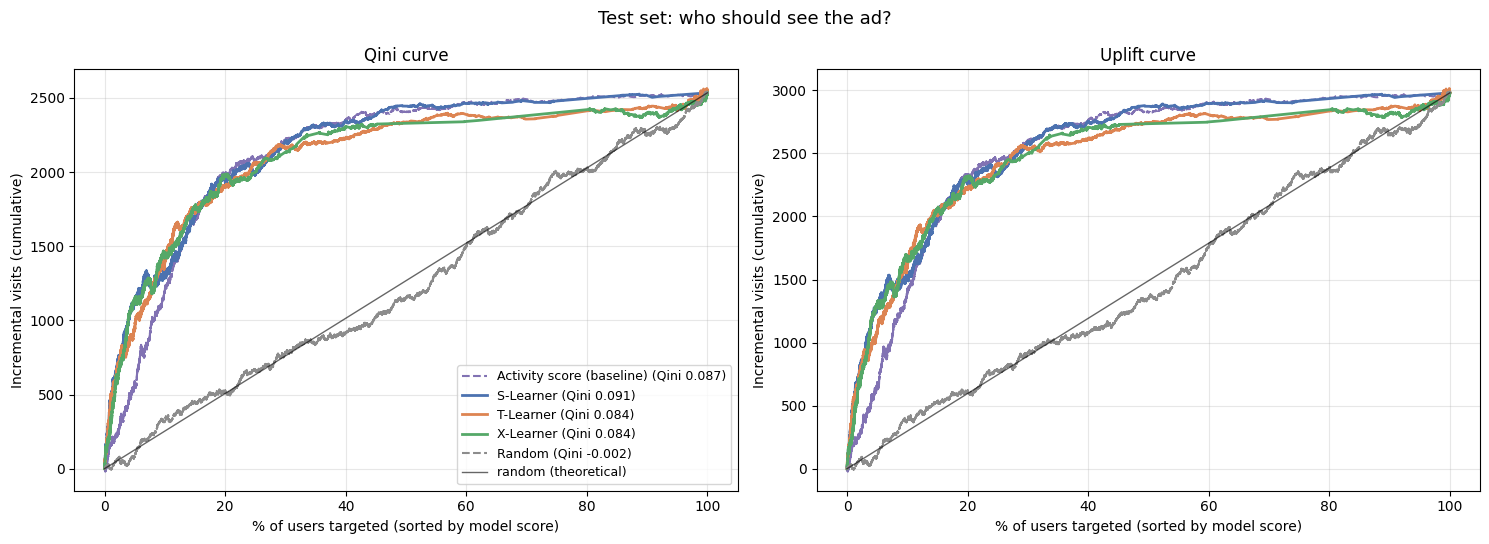

In [8]:
colors = {"S-Learner": "#4C72B0", "T-Learner": "#DD8452", "X-Learner": "#55A868",
          "Activity score (baseline)": "#8172B3", "Random": "#8C8C8C"}
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, curve_fn, title in [(axes[0], qini_curve, "Qini curve"), (axes[1], uplift_curve, "Uplift curve")]:
    for name, u in preds.items():
        x, y = curve_fn(yte, u, tte)
        frac = x / x.max()
        ls = "--" if name in ("Random", "Activity score (baseline)") else "-"
        ax.plot(frac * 100, y, ls=ls, lw=2 if ls == "-" else 1.5, color=colors[name],
                label=f"{name} (Qini {results.loc[name, 'qini_auc']:.3f})")
    x, y = curve_fn(yte, preds["Random"], tte)
    ax.plot([0, 100], [0, y[-1]], color="black", lw=1, alpha=0.6, label="random (theoretical)")
    ax.set_xlabel("% of users targeted (sorted by model score)")
    ax.set_ylabel("Incremental visits (cumulative)")
    ax.set_title(title)
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=9, loc="lower right")
fig.suptitle("Test set: who should see the ad?", fontsize=13)
fig.tight_layout()
fig.savefig(FIG / "07_qini_uplift_curves.png", dpi=110)
plt.show()

## 8.6 Actual uplift per predicted-uplift decile
A good model shows a falling staircase: the highest actual lift in decile 1 and the lowest in decile 10.

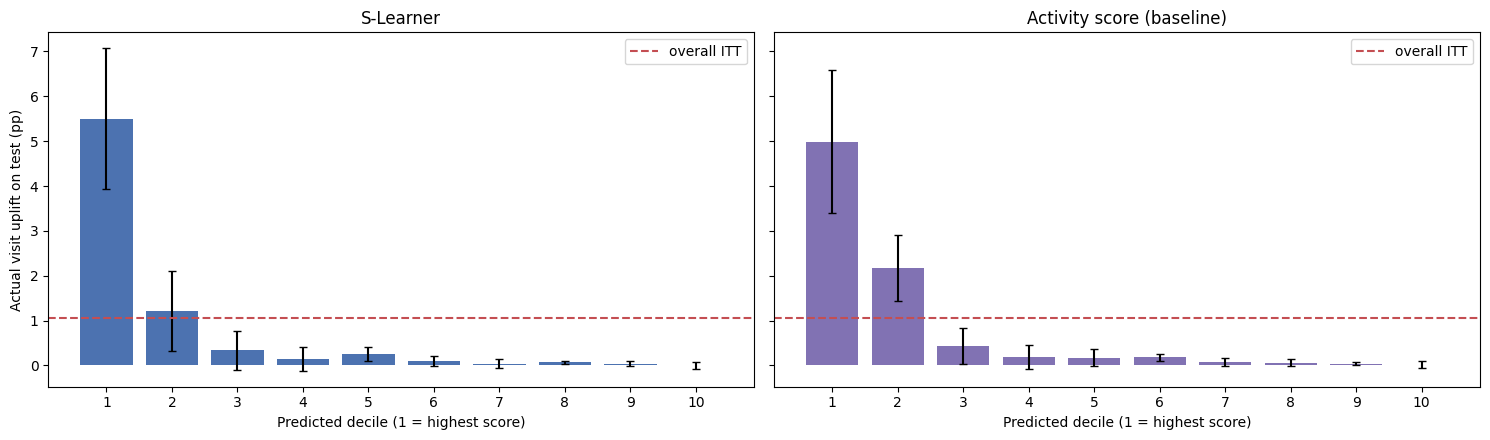

,n,pred_uplift,rate_t,rate_c,actual_uplift,se
bin,,,,,,
1,27960,0.04887,0.35214,0.29717,0.05497,0.00801
2,27959,0.00958,0.09260,0.08039,0.01220,0.00457
3,27959,0.00212,0.02095,0.01752,0.00342,0.00221
4,27959,0.00078,0.00807,0.00654,0.00152,0.00136
5,27959,0.00032,0.00442,0.00189,0.00253,0.00080
6,27959,0.00012,0.00198,0.00096,0.00102,0.00056
7,27959,0.00004,0.00135,0.00096,0.00039,0.00053
8,27959,0.00002,0.00076,0.00000,0.00076,0.00018
9,27959,0.00001,0.00067,0.00024,0.00044,0.00029


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, name in zip(axes, [best_uplift, "Activity score (baseline)"]):
    b = uplift_by_bin(yte, preds[name], tte, 10)
    ax.bar(b.index.astype(int), b.actual_uplift * 100, yerr=1.96 * b.se * 100, color=colors[name], capsize=3)
    ax.axhline((yte[tte == 1].mean() - yte[tte == 0].mean()) * 100, color="#C44E52", ls="--", label="overall ITT")
    ax.set_xticks(range(1, 11))
    ax.set_xlabel("Predicted decile (1 = highest score)")
    ax.set_title(name)
    ax.legend()
axes[0].set_ylabel("Actual visit uplift on test (pp)")
fig.tight_layout()
fig.savefig(FIG / "07_uplift_by_decile.png", dpi=110)
plt.show()
uplift_by_bin(yte, preds[best_uplift], tte, 10)

## 8.7 Is the uplift model just finding "active users"?

If the uplift score and the activity score produce almost the same ranking, the model is really learning baseline activity.

In [10]:
from scipy.stats import spearmanr
act = preds["Activity score (baseline)"]
corr_tbl = pd.Series({name: spearmanr(preds[name], act).correlation
                      for name in ["S-Learner", "T-Learner", "X-Learner"]}, name="Spearman ρ with activity score")
corr_tbl.to_frame()

,Spearman ρ with activity score
S-Learner,0.95972
T-Learner,0.57875
X-Learner,0.50205


In [11]:
# Top-20% overlap between best uplift model and activity score
k = int(0.2 * len(test))
top_u = set(np.argsort(-preds[best_uplift])[:k])
top_a = set(np.argsort(-act)[:k])
print(f"Top-20% overlap ({best_uplift} vs activity): {len(top_u & top_a) / k:.0%}")

Top-20% overlap (S-Learner vs activity): 91%


### Secondary metric: the same models' Qini on conversion (models were trained on visit)

In [12]:
conv = pd.DataFrame({name: uplift_metrics(test.conversion.values, u, tte) for name, u in preds.items()}).T
conv.sort_values("qini_auc", ascending=False)

,qini_auc,uplift_auc,uplift_at_10,uplift_at_20,uplift_at_30
Activity score (baseline),0.23794,0.00799,0.01082,0.00665,0.00474
S-Learner,0.23484,0.00787,0.00990,0.00690,0.00482
X-Learner,0.21540,0.00721,0.00901,0.00616,0.00451
T-Learner,0.20590,0.00689,0.00997,0.00640,0.00449
Random,0.00471,0.00015,0.00208,0.00144,0.00148


## 8.8 Save the best model (for Step 9 and the app)

In [13]:
final_name = best_uplift
final_model = fitted[(final_name, best_cfg[final_name])]
joblib.dump({"model": final_model, "name": final_name, "config": best_cfg[final_name], "features": FEATURES},
            MODELS / "best_uplift_model.joblib")
joblib.dump({"model": fitted[("Activity score (baseline)", best_cfg["Activity score (baseline)"])], "features": FEATURES},
            MODELS / "activity_baseline.joblib")

scores = test[FEATURES + ["treatment", "exposure", "visit", "conversion"]].copy()
for name, u in preds.items():
    scores[f"score_{name.split(' ')[0].lower().replace('-', '_')}"] = u
scores.to_parquet(MODELS / "test_scores.parquet")

with mlflow.start_run(run_name=f"FINAL | {final_name}"):
    mlflow.set_tags({"model": final_name, "stage": "final"})
    mlflow.log_params({**DEFAULT_PARAMS, **CONFIGS[best_cfg[final_name]]})
    mlflow.log_metrics({f"test_{k}": float(v) for k, v in results.loc[final_name].drop(["config"]).items()})
    mlflow.log_artifact(str(MODELS / "best_uplift_model.joblib"))
print("Saved:", [p.name for p in MODELS.iterdir()])

Saved: ['activity_baseline.joblib', 'best_uplift_model.joblib', 'test_scores.parquet']


## 8.9 Comparison table

In [14]:
table = results.drop(columns=["config"]).copy()
table.insert(0, "config", [best_cfg.get(n, "-") for n in table.index])
for k in ["uplift_at_10", "uplift_at_20", "uplift_at_30"]:
    table[k] = table[k] * 100
table = table.rename(columns={"uplift_at_10": "uplift@10% (pp)", "uplift_at_20": "uplift@20% (pp)", "uplift_at_30": "uplift@30% (pp)"})
table

,config,qini_auc,uplift_auc,uplift@10% (pp),uplift@20% (pp),uplift@30% (pp),qini_ci_low,qini_ci_high
model,,,,,,,,
S-Learner,strong_reg,0.09067,0.03579,5.49820,4.06625,3.08431,0.07322,0.11251
Activity score (baseline),regularized,0.08713,0.03447,4.99187,4.13559,3.10209,0.06918,0.10894
X-Learner,strong_reg,0.08428,0.03322,5.95133,4.12016,2.97547,0.06700,0.11033
T-Learner,strong_reg,0.08424,0.03321,5.76651,3.96698,3.02959,0.06794,0.10684
Random,-,-0.00188,-0.00077,1.33800,1.10409,1.10011,-0.01429,0.01106


## Key takeaways (Step 8)

| Model (test set) | Qini AUC [95% CI] | uplift@10% | uplift@20% | uplift@30% |
|---|---|---|---|---|
| **S-Learner** (strong_reg) | **0.091** [0.073, 0.113] | 5.50 pp | 4.07 pp | 3.08 pp |
| Activity score (baseline) | 0.087 [0.069, 0.109] | 4.99 pp | 4.14 pp | 3.10 pp |
| X-Learner (strong_reg) | 0.084 [0.067, 0.110] | **5.95 pp** | 4.12 pp | 2.98 pp |
| T-Learner (strong_reg) | 0.084 [0.068, 0.107] | 5.77 pp | 3.97 pp | 3.03 pp |
| Random | −0.002 | 1.34 pp | 1.10 pp | 1.10 pp |

1. **Every model is ~4–5× better than random.** The top 10% of users show a ~5.5–6 pp lift vs ~1.1 pp with random targeting.
   By the Qini curve, targeting the top 20% captures **~75–80% of incremental visits**.
2. **Best model: S-Learner** (highest Qini). It beats the activity baseline *statistically* (paired bootstrap: +0.0035,
   CI [0.0007, 0.0063], ahead in 99.5% of resamples), but the gap is small (~4%). The differences from T and X are not significant (the CIs cross zero).
3. **⚠️ Honest finding: the uplift model ≈ "target active users".** The S-Learner's Spearman ρ with the activity score is 0.96,
   and the top-20% overlap is 91%. In this dataset, users who already visit more also show the largest absolute ad effect.
   A big reason is that **exposure itself is concentrated on active users** (Step 7: 15% exposure in D10, 0.1% in D1).
   In other words ITT(x) ≈ exposure_rate(x) × CACE(x), and the exposure rate rises steeply with activity.
4. **Uplift models add value in the top ~10%:** the Qini curve rises faster than the activity score at the start.
   uplift@10% is 5.5–6.0 pp there vs 5.0 pp for activity. After 20% the two converge. **Uplift models matter most for small budgets.**
5. **T/X-Learners rank users differently** (ρ ≈ 0.5–0.58 with activity) but reach almost the same Qini. They try to find more
   "persuadable" users, but the control group is small (only ~4,800 control visits in train), so the signal is noisy.
   **Regularization helped these two the most:** validation Qini went from 0.063 → 0.080 for T-Learner and 0.071 → 0.089 for X-Learner.
6. **On conversion** (models were trained on visit), the activity baseline is slightly ahead (Qini 0.238 vs S 0.235). The pattern is the same.

**Decision:** Step 9 uses the **S-Learner** (best Qini, simplest, significantly better than activity).
The activity score stays as a benchmark, because the business should know that a simple rule delivers ~96% of the value.

**MLflow:** 17 runs tracked (12 tuning + 4 test + 1 final). To open the UI, run this from the project folder:
`mlflow ui --backend-store-uri sqlite:///mlflow.db`